In [1]:

import sys

import matplotlib
import numpy
import pandas
import scipy
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    scipy.__version__,
    sklearn.__version__,
    matplotlib.__version__
)


3.11.9 1.26.4 2.2.1 1.12.0 1.4.1.post1 3.8.3


In [2]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

SEED = 2305

df = pd.read_csv("data/drybean.csv")

class_label = df.pop("Class").to_numpy()

X = df.to_numpy(dtype=float)
features = list(df.columns)
n = len(X)

print(X.shape, "missing values:", int(np.isnan(X).sum()))

(13543, 16) missing values: 0


In [3]:

Xs = StandardScaler().fit_transform(X)


# Task 5 — Clustering & PCA

Course: MOP 3231 — Machine Learning (Python)

Dataset: UCI Dry Bean

Student SEED: 2305


## Part 1 — Setup and Data Audit

### 1.1 Descriptive Statistics and Variance Shares

In [4]:

# Descriptive statistics of the raw features
audit_table = pd.DataFrame({
    "Mean": df.mean(),
    "Std": df.std(ddof=0),
    "Minimum": df.min(),
    "Maximum": df.max()
})

# Population variance of each feature
variances = df.var(ddof=0)

# Share of total variance
variance_shares = variances / variances.sum()

audit_table["Variance share"] = variance_shares
audit_table["Variance share (%)"] = variance_shares * 100

display(audit_table.style.format("{:.4g}"))


,Mean,Std,Minimum,Maximum,Variance share,Variance share (%)
Area,5.305e+04,2.939e+04,2.042e+04,2.546e+05,0.4924,49.24
Perimeter,855,214.7,524.7,1985,2.628e-05,0.002628
MajorAxisLength,319.9,85.81,183.6,738.9,4.196e-06,0.0004196
MinorAxisLength,202.4,45.05,122.5,460.2,1.157e-06,0.0001157
AspectRatio,1.581,0.2452,1.025,2.43,3.428e-11,3.428e-09
Eccentricity,0.7503,0.09185,0.219,0.9114,4.809e-12,4.809e-10
ConvexArea,5.377e+04,2.984e+04,2.068e+04,2.633e+05,0.5076,50.76
EquivDiameter,253,59.31,161.2,569.4,2.005e-06,0.0002005
Extent,0.7498,0.04894,0.5553,0.8662,1.365e-12,1.365e-10
Solidity,0.9872,0.00465,0.9192,0.9947,1.232e-14,1.232e-12


In [5]:

# Rank features by their contribution to total variance
variance_ranking = variance_shares.sort_values(ascending=False)

top_two = variance_ranking.head(2)
combined_share = top_two.sum()

print("Two dominant features:")

for feature, share in top_two.items():
    print(f"{feature}: {share:.8f} ({share * 100:.6f}%)")

print(f"\nCombined variance share: {combined_share:.8f}")
print(f"Combined percentage: {combined_share * 100:.6f}%")

print(f"Total variance share: {variance_shares.sum():.6f}")


Two dominant features:
ConvexArea: 0.50760969 (50.760969%)
Area: 0.49235668 (49.235668%)

Combined variance share: 0.99996637
Combined percentage: 99.996637%
Total variance share: 1.000000


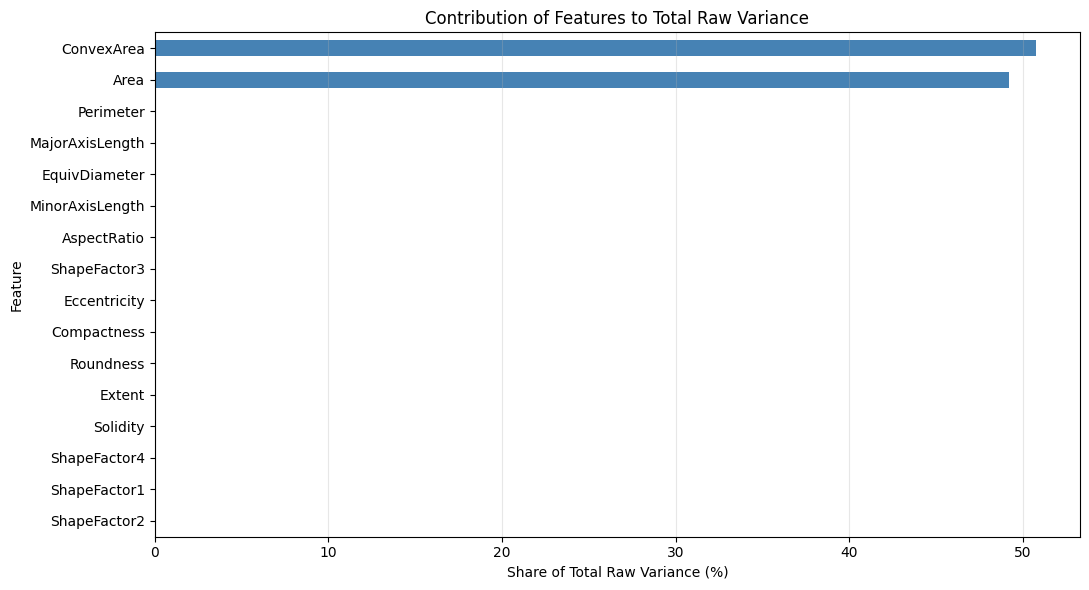

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

variance_ranking.sort_values().mul(100).plot(
    kind="barh",
    color="steelblue"
)

plt.xlabel("Share of Total Raw Variance (%)")
plt.ylabel("Feature")
plt.title("Contribution of Features to Total Raw Variance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 1.2 Correlation Analysis

In [7]:

# Pearson correlation matrix
corr_matrix = df.corr(method="pearson")

strong_pairs = []

# Each feature pair is counted only once
for i in range(len(features)):
    for j in range(i + 1, len(features)):

        correlation = corr_matrix.iloc[i, j]

        if abs(correlation) > 0.95:
            strong_pairs.append({
                "Feature 1": features[i],
                "Feature 2": features[j],
                "Correlation": correlation,
                "Absolute correlation": abs(correlation)
            })

strong_corr_table = pd.DataFrame(strong_pairs)

strong_corr_table = strong_corr_table.sort_values(
    "Absolute correlation",
    ascending=False
).reset_index(drop=True)

print("Number of strongly correlated pairs:", len(strong_pairs))

display(strong_corr_table.round(6))


Number of strongly correlated pairs: 15


,Feature 1,Feature 2,Correlation,Absolute correlation
0,Area,ConvexArea,0.999940,0.999940
1,Compactness,ShapeFactor3,0.998684,0.998684
2,Perimeter,EquivDiameter,0.991453,0.991453
3,AspectRatio,Compactness,-0.987644,0.987644
4,ConvexArea,EquivDiameter,0.985255,0.985255
5,Area,EquivDiameter,0.984998,0.984998
6,Eccentricity,ShapeFactor3,-0.981058,0.981058
7,AspectRatio,ShapeFactor3,-0.978528,0.978528
8,Perimeter,MajorAxisLength,0.977561,0.977561
9,Eccentricity,Compactness,-0.970308,0.970308


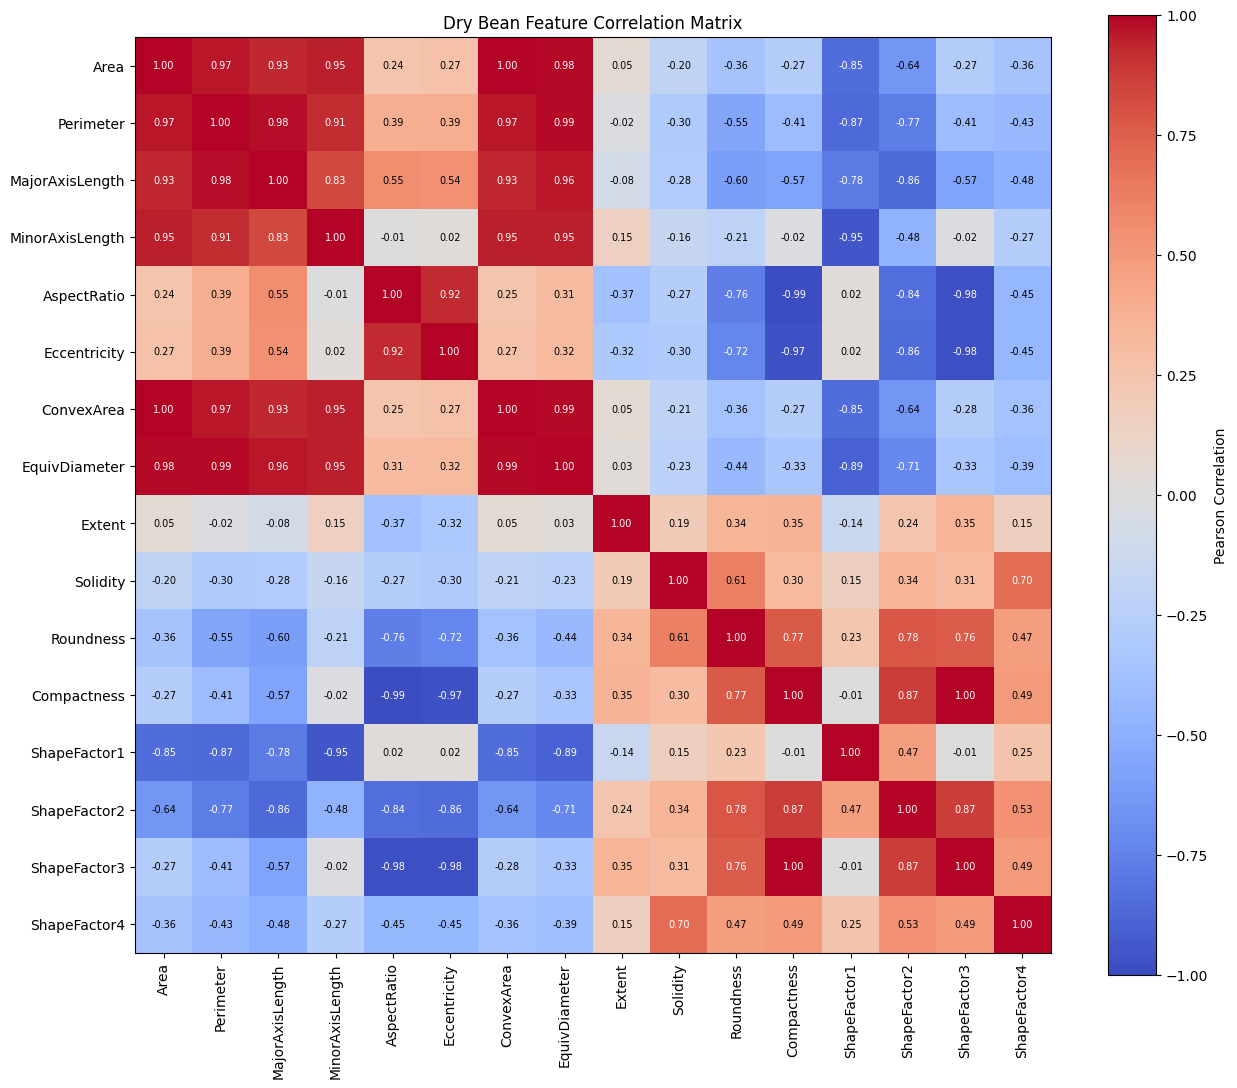

In [8]:

fig, ax = plt.subplots(figsize=(13, 11))

im = ax.imshow(
    corr_matrix.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(np.arange(len(features)))
ax.set_yticks(np.arange(len(features)))

ax.set_xticklabels(features, rotation=90)
ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        value = corr_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if abs(value) > 0.7 else "black"
        )

fig.colorbar(im, ax=ax, label="Pearson Correlation")

ax.set_title("Dry Bean Feature Correlation Matrix")

plt.tight_layout()
plt.show()


In [9]:

scaling_check = pd.DataFrame({
    "Feature": features,
    "Raw mean": X.mean(axis=0),
    "Raw std": X.std(axis=0, ddof=0),
    "Scaled mean": Xs.mean(axis=0),
    "Scaled std": Xs.std(axis=0, ddof=0)
})

display(scaling_check.round(6))

print(
    "Scaled means close to zero:",
    np.allclose(Xs.mean(axis=0), 0)
)

print(
    "Scaled stds close to one:",
    np.allclose(Xs.std(axis=0), 1)
)


,Feature,Raw mean,Raw std,Scaled mean,Scaled std
0,Area,53048.460385,29391.353152,0.0,1.0
1,Perimeter,854.993406,214.714756,-0.0,1.0
2,MajorAxisLength,319.895602,85.806092,0.0,1.0
3,MinorAxisLength,202.365321,45.049968,-0.0,1.0
4,AspectRatio,1.581075,0.245236,0.0,1.0
5,Eccentricity,0.750315,0.091854,-0.0,1.0
6,ConvexArea,53767.986709,29843.146672,0.0,1.0
7,EquivDiameter,253.034094,59.305519,0.0,1.0
8,Extent,0.749829,0.048937,-0.0,1.0
9,Solidity,0.987152,0.004650,0.0,1.0


Scaled means close to zero: True
Scaled stds close to one: True


### Part 1 — Results and Discussion

**Descriptive Statistics**

The dataset contains 13,543 observations and 16 numerical features. The descriptive statistics reveal substantial differences in feature scales, particularly between area-based measurements and dimensionless shape descriptors.

For example, Area has a standard deviation of approximately 29,391.35, whereas Solidity has a standard deviation of only 0.004650.

**Variance Analysis**

The two dominant features are ConvexArea and Area, accounting for 50.760969% and 49.235668% of the total raw variance, respectively.

Their combined contribution is 99.996637%, leaving only 0.003363% of the total variance to the remaining 14 features.

Consequently, Euclidean distances in the raw feature space are dominated by area-related measurements. Without standardization, clustering would primarily reflect differences in bean size rather than the complete set of shape characteristics.

**Correlation Analysis**

A total of 15 unique feature pairs have an absolute Pearson correlation greater than 0.95.

The strongest positive correlation was observed between Area and ConvexArea, with a coefficient of 0.999940. This is expected because both features describe closely related geometric properties of the same bean grain.

The strong correlations also indicate substantial redundancy among the numerical features, motivating the use of dimensionality reduction through PCA in Part 6.

**Standardization**

StandardScaler was applied to all 16 numerical features. The verification confirmed that the standardized features have means close to zero and standard deviations equal to one.

Standardization prevents features with large numerical scales from disproportionately dominating Euclidean distances, although correlations between features remain.

**Conclusion**

The data audit demonstrates that feature scaling is essential when considering all size and shape measurements in distance-based clustering. The class labels were kept separate and were not used in the analysis.

## Part 2 — K-Means and Scaling

### 2.1 Lloyd's K-Means From Scratch

In [10]:

def lloyd_kmeans(X, init_centers, max_iter=300):
    """Return (labels, centers, inertia, n_iter)."""
    import numpy as np

    X = np.asarray(X, dtype=float)
    centers = np.asarray(init_centers, dtype=float).copy()

    n = len(X)
    k = len(centers)

    previous_labels = None

    for n_iter in range(1, max_iter + 1):

        # Squared Euclidean distances to every center
        distances = np.sum(
            (X[:, None, :] - centers[None, :, :]) ** 2,
            axis=2
        )

        # Assign each observation to its closest center
        labels = np.argmin(distances, axis=1)

        # Update centers
        new_centers = centers.copy()

        for j in range(k):
            cluster_points = X[labels == j]

            if len(cluster_points) > 0:
                new_centers[j] = cluster_points.mean(axis=0)

        centers = new_centers

        # Stop when cluster assignments do not change
        if previous_labels is not None:
            if np.array_equal(labels, previous_labels):
                break

        previous_labels = labels.copy()

    # Calculate inertia using the final centers
    inertia = float(
        np.sum((X - centers[labels]) ** 2)
    )

    return labels, centers, inertia, n_iter


In [11]:

X_example = np.array([
    [0], [1], [2], [10], [11], [12]
], dtype=float)

init_example = np.array([
    [0], [12]
], dtype=float)

labels_example, centers_example, inertia_example, iterations_example = (
    lloyd_kmeans(X_example, init_example)
)

print("Labels:", labels_example)
print("Centers:", centers_example.ravel())
print("Inertia:", inertia_example)
print("Iterations:", iterations_example)

assert np.array_equal(
    labels_example, [0, 0, 0, 1, 1, 1]
)

assert np.allclose(centers_example, [[1], [11]])
assert np.isclose(inertia_example, 4.0)
assert iterations_example == 2

print("All example tests passed")


Labels: [0 0 0 1 1 1]
Centers: [ 1. 11.]
Inertia: 4.0
Iterations: 2
All example tests passed


In [12]:

# Empty cluster must retain its original center
lab, cen, ine, nit = lloyd_kmeans(
    np.array([[0.0], [2.0]]),
    np.array([[0.0], [100.0]])
)

assert np.allclose(cen, [[1.0], [100.0]])

# Equal distances: choose the lower center index
lab, cen, ine, nit = lloyd_kmeans(
    np.array([[1.0]]),
    np.array([[0.0], [2.0]]),
    max_iter=1
)

assert lab[0] == 0

# Centers must be updated even after the last assignment
lab, cen, ine, nit = lloyd_kmeans(
    X_example,
    init_example,
    max_iter=1
)

assert np.allclose(cen, [[1.0], [11.0]])
assert nit == 1

print("All additional edge-case tests passed")


All additional edge-case tests passed


In [13]:

from sklearn.cluster import KMeans

# Seeded initial centers, exactly as specified
init_indices = np.random.default_rng(SEED).choice(
    n, 7, replace=False
)

init = Xs[init_indices]

manual_labels, manual_centers, manual_inertia, manual_iterations = (
    lloyd_kmeans(Xs, init)
)

# Scikit-learn comparison
sklearn_lloyd = KMeans(
    n_clusters=7,
    init=init,
    n_init=1,
    algorithm="lloyd",
    tol=0.0,
    max_iter=300
).fit(Xs)

print("Manual inertia:", manual_inertia)
print("Sklearn inertia:", sklearn_lloyd.inertia_)

print(
    "Labels identical:",
    np.array_equal(manual_labels, sklearn_lloyd.labels_)
)

print(
    "Centers equal:",
    np.allclose(
        manual_centers,
        sklearn_lloyd.cluster_centers_,
        rtol=1e-6
    )
)

print(
    "Inertia equal:",
    np.isclose(
        manual_inertia,
        sklearn_lloyd.inertia_,
        rtol=1e-6
    )
)

print(
    "Maximum center difference:",
    np.max(
        np.abs(
            manual_centers -
            sklearn_lloyd.cluster_centers_
        )
    )
)

print("Manual iterations:", manual_iterations)
print("Sklearn iterations:", sklearn_lloyd.n_iter_)


Manual inertia: 53006.81498962084
Sklearn inertia: 53006.81498962085
Labels identical: True
Centers equal: True
Inertia equal: True
Maximum center difference: 3.774758283725532e-15
Manual iterations: 52
Sklearn iterations: 52


In [14]:

from sklearn.metrics import silhouette_score

# K-Means on raw features
kmeans_raw = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=SEED
).fit(X)

# K-Means on standardized features
kmeans_scaled = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=SEED
).fit(Xs)

raw_silhouette = silhouette_score(
    X,
    kmeans_raw.labels_,
    sample_size=4000,
    random_state=SEED
)

scaled_silhouette = silhouette_score(
    Xs,
    kmeans_scaled.labels_,
    sample_size=4000,
    random_state=SEED
)

kmeans_comparison = pd.DataFrame({
    "Data space": ["Raw", "Standardized"],
    "Inertia": [
        kmeans_raw.inertia_,
        kmeans_scaled.inertia_
    ],
    "Silhouette": [
        raw_silhouette,
        scaled_silhouette
    ]
})

display(kmeans_comparison)


,Data space,Inertia,Silhouette
0,Raw,6.125381e+11,0.537804
1,Standardized,4.867134e+04,0.305700


In [15]:

raw_sizes = np.sort(
    np.bincount(kmeans_raw.labels_, minlength=7)
)[::-1]

scaled_sizes = np.sort(
    np.bincount(kmeans_scaled.labels_, minlength=7)
)[::-1]

cluster_sizes = pd.DataFrame({
    "Size rank": np.arange(1, 8),
    "Raw cluster size": raw_sizes,
    "Scaled cluster size": scaled_sizes
})

display(cluster_sizes)

print("Raw total:", raw_sizes.sum())
print("Scaled total:", scaled_sizes.sum())


,Size rank,Raw cluster size,Scaled cluster size
0,1,4206,3159
1,2,3216,3111
2,3,2539,2481
3,4,1907,2033
4,5,1155,1706
5,6,303,533
6,7,217,520


Raw total: 13543
Scaled total: 13543


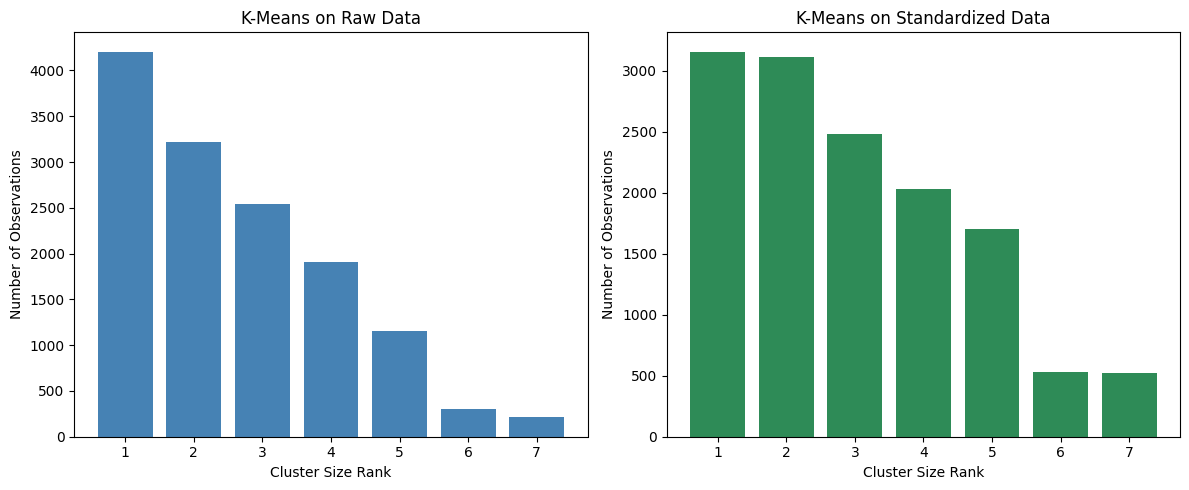

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    np.arange(1, 8),
    raw_sizes,
    color="steelblue"
)
axes[0].set_title("K-Means on Raw Data")
axes[0].set_xlabel("Cluster Size Rank")
axes[0].set_ylabel("Number of Observations")
axes[0].set_xticks(np.arange(1, 8))

axes[1].bar(
    np.arange(1, 8),
    scaled_sizes,
    color="seagreen"
)
axes[1].set_title("K-Means on Standardized Data")
axes[1].set_xlabel("Cluster Size Rank")
axes[1].set_ylabel("Number of Observations")
axes[1].set_xticks(np.arange(1, 8))

plt.tight_layout()
plt.show()


In [17]:

from sklearn.metrics import adjusted_rand_score

area_index = features.index("Area")

X_area = X[:, [area_index]]

kmeans_area = KMeans(
    n_clusters=7,
    n_init=10,
    random_state=SEED
).fit(X_area)

ari_raw_area = adjusted_rand_score(
    kmeans_raw.labels_,
    kmeans_area.labels_
)

ari_scaled_area = adjusted_rand_score(
    kmeans_scaled.labels_,
    kmeans_area.labels_
)

area_comparison = pd.DataFrame({
    "Comparison": [
        "Raw K-Means vs Area-only K-Means",
        "Scaled K-Means vs Area-only K-Means"
    ],
    "Adjusted Rand Index": [
        ari_raw_area,
        ari_scaled_area
    ]
})

display(area_comparison.round(6))

print(f"Raw silhouette: {raw_silhouette:.6f}")
print(f"Scaled silhouette: {scaled_silhouette:.6f}")
print(f"Raw vs Area ARI: {ari_raw_area:.6f}")
print(f"Scaled vs Area ARI: {ari_scaled_area:.6f}")
print(f"Area and ConvexArea variance: {combined_share * 100:.6f}%")


,Comparison,Adjusted Rand Index
0,Raw K-Means vs Area-only K-Means,0.965658
1,Scaled K-Means vs Area-only K-Means,0.385978


Raw silhouette: 0.537804
Scaled silhouette: 0.305700
Raw vs Area ARI: 0.965658
Scaled vs Area ARI: 0.385978
Area and ConvexArea variance: 99.996637%


### Part 2 — Results and Discussion

**Manual K-Means Implementation**

Lloyd's K-Means algorithm was implemented from scratch using NumPy. The implementation follows the required assignment and centroid-update rules, including tie-breaking by the smallest cluster index, retaining the previous center for empty clusters, and updating centers after the final assignment step.

The manually implemented algorithm was compared with scikit-learn's KMeans using identical seeded initial centers.

The manual inertia was 53006.81498962084, while scikit-learn produced an inertia of 53006.81498962085. Cluster labels were identical, and the maximum absolute difference between cluster centers was approximately 3.77 × 10⁻¹⁵.

Both implementations converged after 52 iterations. These results confirm agreement between the manual implementation and scikit-learn up to floating-point precision.

**Raw vs. Standardized Data**

K-Means with seven clusters was applied to both raw and standardized data using ten initializations.

The raw-data clustering achieved an inertia of approximately 6.125381 × 10¹¹ and a silhouette score of 0.537804.

The standardized-data clustering achieved an inertia of approximately 48671.34 and a silhouette score of 0.305700.

The inertia values cannot be directly compared because the two feature spaces use different scales.

Although the raw-data clustering achieved a higher silhouette score, this does not establish that it provides a more informative grouping of bean grains.

**Cluster Size Analysis**

The raw-data cluster sizes, in descending order, were 4206, 3216, 2539, 1907, 1155, 303, and 217.

The standardized-data cluster sizes were 3159, 3111, 2481, 2033, 1706, 533, and 520.

Both clusterings included all 13,543 observations. Standardization produced a more balanced distribution of cluster sizes, although balanced sizes alone do not establish superior clustering quality.

**Comparison with Area-Only Clustering**

The adjusted Rand index between raw K-Means and Area-only K-Means was 0.965658, indicating almost identical partitions.

In contrast, the adjusted Rand index between standardized K-Means and Area-only K-Means was 0.385978.

As established in Part 1, Area and ConvexArea account for 99.996637% of the total raw variance. Consequently, Euclidean distances in the raw feature space are overwhelmingly influenced by these two area-based measurements.

The higher raw silhouette therefore primarily reflects separation by bean size rather than separation based on the complete set of size and shape descriptors.

**Choice of Feature Space**

I recommend using the standardized feature space for the remaining clustering experiments.

Standardization prevents features with large numerical scales from dominating distances and allows all 16 measurements to contribute on a comparable variance scale. The lower agreement with Area-only clustering supports the interpretation that standardized K-Means captures structure beyond bean area.

This decision was made exclusively using internal clustering measures and the feature audit, without accessing the Class labels.

## Part 3 — Choosing the Number of Clusters

### 3.1 Inertia and Silhouette Analysis

In [18]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    ).fit(Xs)

    silhouette = silhouette_score(
        Xs,
        model.labels_,
        sample_size=4000,
        random_state=SEED
    )

    k_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette
    })

k_table = pd.DataFrame(k_results)

display(k_table.round(6))

best_silhouette_k = int(
    k_table.loc[k_table["Silhouette"].idxmax(), "k"]
)

print("Best k by silhouette:", best_silhouette_k)
print("Best silhouette:", k_table["Silhouette"].max())


,k,Inertia,Silhouette
0,2,129194.064510,0.394098
1,3,94331.740541,0.399733
2,4,75993.194900,0.340655
3,5,61624.676280,0.353469
4,6,54900.630904,0.354363
5,7,48671.341829,0.305700
6,8,45083.071101,0.302002
7,9,41904.816092,0.300326
8,10,39682.241695,0.287132


Best k by silhouette: 3
Best silhouette: 0.39973253865368447


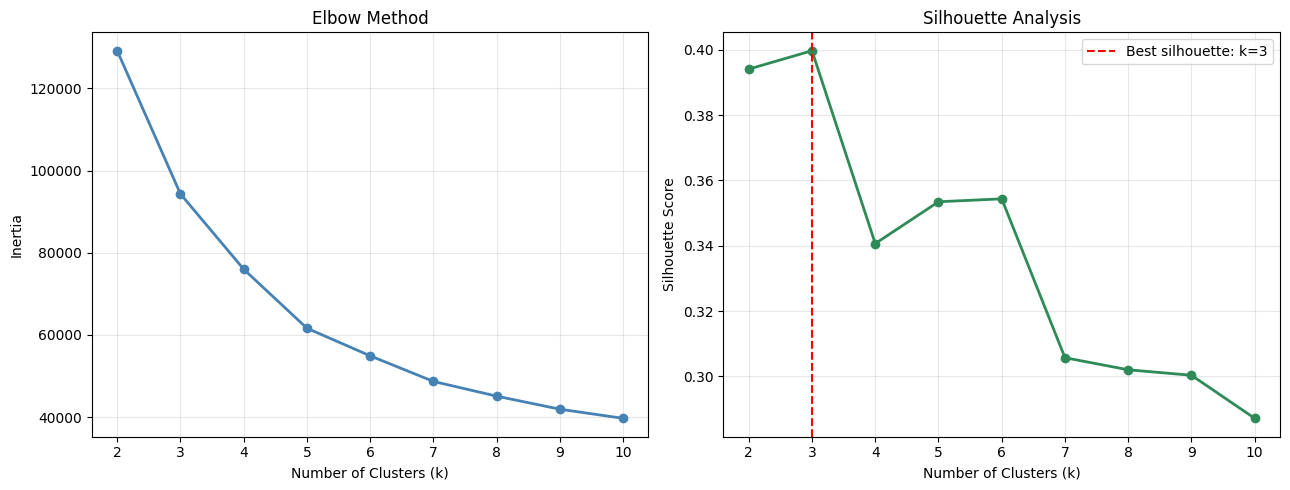

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow method
axes[0].plot(
    k_table["k"],
    k_table["Inertia"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(2, 11))
axes[0].grid(alpha=0.3)

# Silhouette analysis
axes[1].plot(
    k_table["k"],
    k_table["Silhouette"],
    marker="o",
    linewidth=2,
    color="seagreen"
)

axes[1].axvline(
    best_silhouette_k,
    color="red",
    linestyle="--",
    label=f"Best silhouette: k={best_silhouette_k}"
)

axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(range(2, 11))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 3.2 K-Means Stability Analysis

In [20]:

from itertools import combinations
from sklearn.metrics import adjusted_rand_score

stability_labels = []
stability_inertias = []
stability_rows = []

for i in range(10):

    model = KMeans(
        n_clusters=7,
        n_init=1,
        random_state=SEED + i
    ).fit(Xs)

    stability_labels.append(model.labels_.copy())
    stability_inertias.append(model.inertia_)

    stability_rows.append({
        "Run": i,
        "Random state": SEED + i,
        "Inertia": model.inertia_,
        "Iterations": model.n_iter_
    })

stability_table = pd.DataFrame(stability_rows)

display(stability_table.round(6))


,Run,Random state,Inertia,Iterations
0,0,2305,51639.382170,11
1,1,2306,48671.467249,10
2,2,2307,53014.890840,20
3,3,2308,48671.437847,12
4,4,2309,48671.355982,9
5,5,2310,48671.483238,9
6,6,2311,51239.365562,13
7,7,2312,53007.918011,40
8,8,2313,51237.984255,18
9,9,2314,48671.461654,17


In [21]:

pairwise_aris = []

ari_matrix = np.eye(10)

for i, j in combinations(range(10), 2):

    ari = adjusted_rand_score(
        stability_labels[i],
        stability_labels[j]
    )

    pairwise_aris.append(ari)

    ari_matrix[i, j] = ari
    ari_matrix[j, i] = ari

mean_stability_ari = np.mean(pairwise_aris)
min_stability_ari = np.min(pairwise_aris)

min_inertia = np.min(stability_inertias)
max_inertia = np.max(stability_inertias)

print("Number of pairwise comparisons:", len(pairwise_aris))
print(f"Mean pairwise ARI: {mean_stability_ari:.6f}")
print(f"Minimum pairwise ARI: {min_stability_ari:.6f}")

print(f"Minimum inertia: {min_inertia:.6f}")
print(f"Maximum inertia: {max_inertia:.6f}")

print(
    f"Inertia range: "
    f"{max_inertia - min_inertia:.6f}"
)


Number of pairwise comparisons: 45
Mean pairwise ARI: 0.759239
Minimum pairwise ARI: 0.449025
Minimum inertia: 48671.355982
Maximum inertia: 53014.890840
Inertia range: 4343.534858


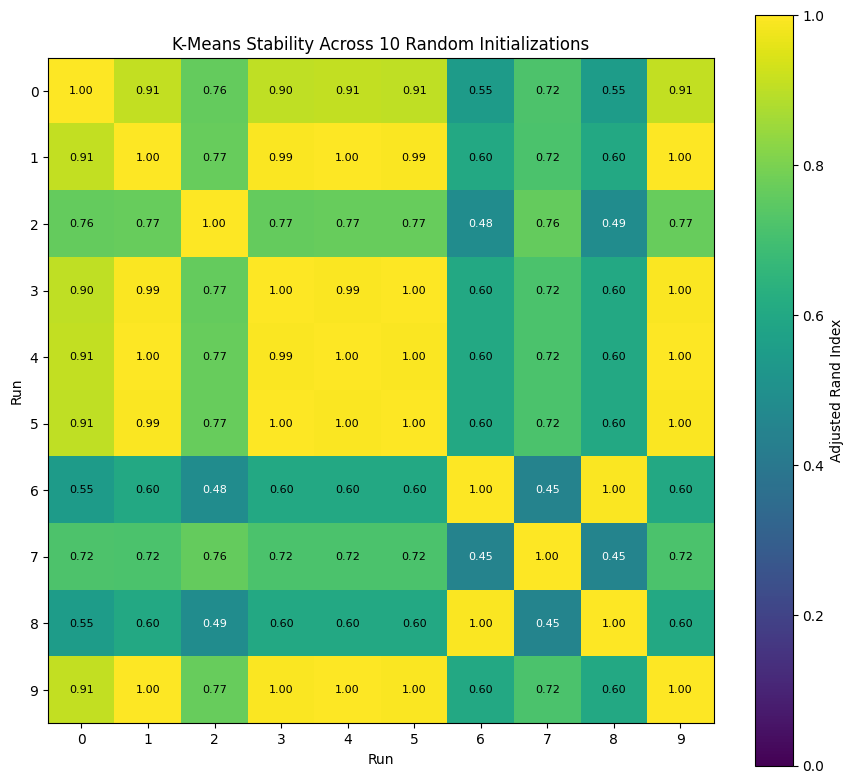

In [22]:

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(
    ari_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(10))
ax.set_yticks(range(10))

ax.set_xlabel("Run")
ax.set_ylabel("Run")

for i in range(10):
    for j in range(10):

        ax.text(
            j, i,
            f"{ari_matrix[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if ari_matrix[i, j] < 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Adjusted Rand Index")

ax.set_title("K-Means Stability Across 10 Random Initializations")

plt.tight_layout()
plt.show()


### Part 3 — Results and Discussion

**Inertia and Silhouette Analysis**

K-Means clustering was evaluated on the standardized dataset for k values ranging from 2 to 10, using ten initializations and a silhouette sample of 4,000 observations.

The highest silhouette score was 0.399733, obtained with k = 3. In comparison, k = 7 achieved a silhouette score of 0.305700.

The results suggest that three clusters provide better separation according to the silhouette criterion in the standardized feature space.

**Elbow Method**

Inertia decreased from 129194.064510 at k = 2 to 39682.241695 at k = 10.

A reasonable elbow can be identified around k = 5, where inertia reached 61624.676280. After this point, the additional reduction in inertia becomes less pronounced, suggesting diminishing benefits from increasing the number of clusters.

The elbow is a visual judgment rather than a uniquely defined optimum.

**Clustering Stability**

Ten independent single-initialization K-Means runs were performed at k = 7 using random states from 2305 to 2314.

The 45 pairwise comparisons produced a mean adjusted Rand index of 0.759239 and a minimum adjusted Rand index of 0.449025.

The inertia values ranged from 48671.355982 to 53014.890840, with a total range of 4343.534858.

These results indicate that the clustering solution depends on the initial centroid selection. Although several runs produced nearly identical partitions, others converged to substantially different solutions.

Therefore, using multiple initializations, such as n_init=10, is preferable to relying on a single random initialization, because it reduces the risk of selecting a poor local minimum.

**Recommended Number of Clusters**

Based exclusively on internal clustering measures, I recommend k = 3 because it achieved the highest silhouette score of 0.399733.

The elbow around k = 5 suggests an alternative balance between cluster compactness and model complexity. The observed instability at k = 7 provides an additional reason not to assume that seven clusters are necessarily optimal.

Neither the silhouette maximum nor the estimated elbow supports seven as the preferred number of clusters.

This recommendation was made without accessing the Class labels. Nevertheless, k = 7 will be retained in Parts 4–6 according to the experimental requirements of the assignment.

## Part 4 — Hierarchical Clustering

### 4.1 Seeded Subsample

In [23]:

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, cophenet, dendrogram
from scipy.spatial.distance import pdist

# Seeded subsample exactly as specified
sub_idx = np.random.default_rng(SEED).choice(
    n, 2000, replace=False
)

Xsub = Xs[sub_idx]

print("Original dataset shape:", Xs.shape)
print("Subsample shape:", Xsub.shape)
print("Unique sampled indices:", len(np.unique(sub_idx)))

# Full pairwise distance matrix memory estimates
full_memory = n ** 2 * 8 / 1e6
sub_memory = len(Xsub) ** 2 * 8 / 1e6

print(f"Full distance matrix: {full_memory:.2f} MB")
print(f"Subsample distance matrix: {sub_memory:.2f} MB")


Original dataset shape: (13543, 16)
Subsample shape: (2000, 16)
Unique sampled indices: 2000
Full distance matrix: 1467.30 MB
Subsample distance matrix: 32.00 MB


### 4.2 Linkage Comparison

In [24]:

linkage_methods = [
    "ward",
    "complete",
    "average",
    "single"
]

hierarchical_labels = {}
linkage_matrices = {}
hierarchical_results = []

# Original distances between sampled observations
sub_distances = pdist(Xsub)

# Reuse K-Means labels from Part 2
kmeans_sub_labels = kmeans_scaled.labels_[sub_idx]

for method in linkage_methods:

    # Hierarchical clustering with 7 clusters
    model = AgglomerativeClustering(
        n_clusters=7,
        linkage=method
    )

    labels = model.fit_predict(Xsub)

    hierarchical_labels[method] = labels.copy()

    # Linkage matrix for dendrogram and cophenetic correlation
    Z = linkage(Xsub, method=method)
    linkage_matrices[method] = Z

    cophenetic_corr = cophenet(
        Z, sub_distances
    )[0]

    sizes = np.bincount(labels)

    largest_share = sizes.max() / len(Xsub)

    ari = adjusted_rand_score(
        kmeans_sub_labels,
        labels
    )

    hierarchical_results.append({
        "Linkage": method,
        "Cophenetic correlation": cophenetic_corr,
        "Largest cluster share": largest_share,
        "Largest cluster (%)": largest_share * 100,
        "ARI vs K-Means": ari,
        "Chaining": largest_share > 0.90
    })

hierarchical_table = pd.DataFrame(
    hierarchical_results
)

display(hierarchical_table.round(6))


,Linkage,Cophenetic correlation,Largest cluster share,Largest cluster (%),ARI vs K-Means,Chaining
0,ward,0.605701,0.2435,24.35,0.691392,False
1,complete,0.775300,0.4930,49.30,0.525019,False
2,average,0.847319,0.9460,94.60,0.045187,True
3,single,0.726796,0.9970,99.70,0.001676,True


In [25]:

hierarchical_sizes = pd.DataFrame({
    method: np.sort(
        np.bincount(
            hierarchical_labels[method],
            minlength=7
        )
    )[::-1]

    for method in linkage_methods
})

hierarchical_sizes.index = np.arange(1, 8)
hierarchical_sizes.index.name = "Size rank"

display(hierarchical_sizes)

print("Linkages exhibiting chaining:")

chaining_methods = hierarchical_table[
    hierarchical_table["Largest cluster share"] > 0.90
]

if chaining_methods.empty:
    print("None")
else:
    for _, row in chaining_methods.iterrows():
        print(
            f"{row['Linkage']}: "
            f"{row['Largest cluster (%)']:.4f}%"
        )


,ward,complete,average,single
Size rank,,,,
1,487,986,1892,1994
2,412,621,84,1
3,391,259,15,1
4,349,84,5,1
5,220,39,2,1
6,84,10,1,1
7,57,1,1,1


Linkages exhibiting chaining:
average: 94.6000%
single: 99.7000%


Selected linkage: ward
Last retained merge: 32.315277
First excluded merge: 42.356292
Cut height for 7 clusters: 37.335784


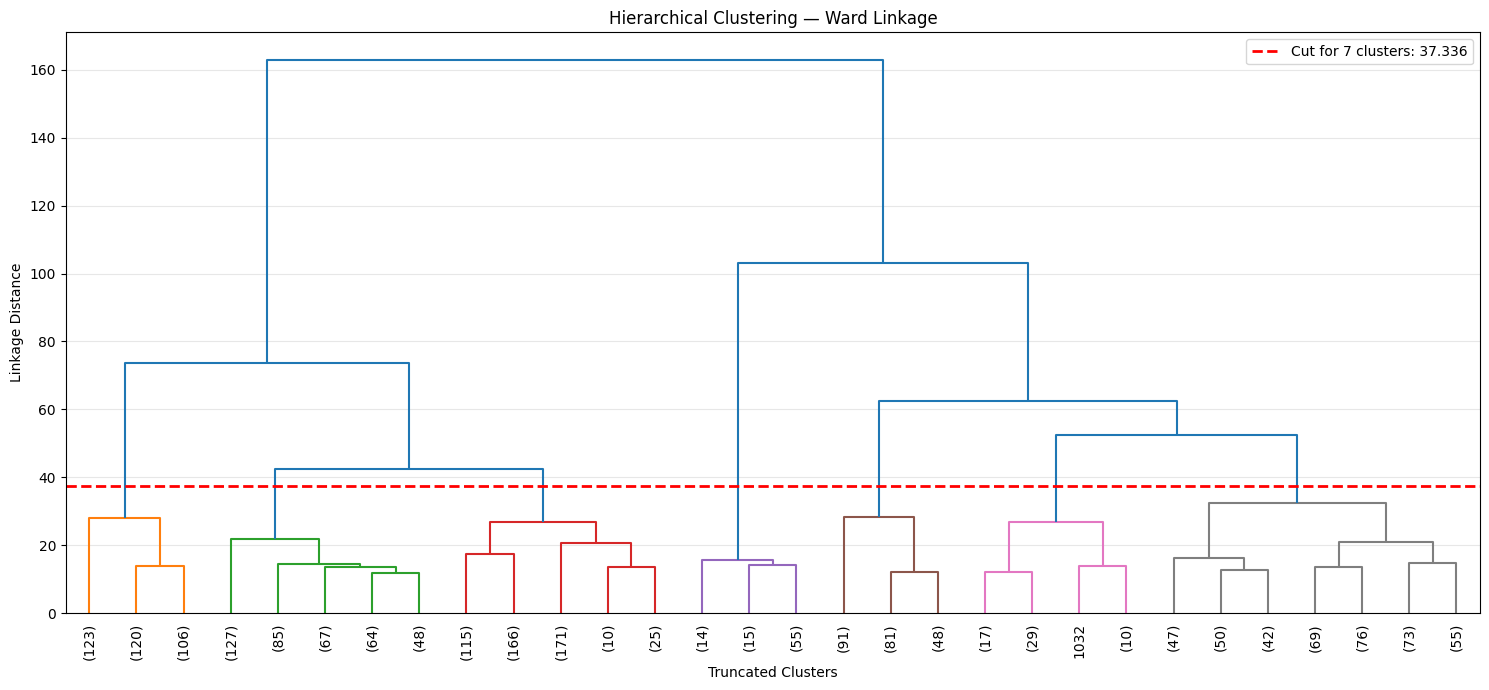

In [26]:

chosen_linkage = "ward"

Z_chosen = linkage_matrices[chosen_linkage]

# Cut height for exactly seven clusters
cut_height = (
    Z_chosen[-7, 2] + Z_chosen[-6, 2]
) / 2

print("Selected linkage:", chosen_linkage)
print(f"Last retained merge: {Z_chosen[-7, 2]:.6f}")
print(f"First excluded merge: {Z_chosen[-6, 2]:.6f}")
print(f"Cut height for 7 clusters: {cut_height:.6f}")

plt.figure(figsize=(15, 7))

dendrogram(
    Z_chosen,
    truncate_mode="lastp",
    p=30,
    color_threshold=cut_height,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.axhline(
    cut_height,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Cut for 7 clusters: {cut_height:.3f}"
)

plt.title(
    f"Hierarchical Clustering — "
    f"{chosen_linkage.capitalize()} Linkage"
)

plt.xlabel("Truncated Clusters")
plt.ylabel("Linkage Distance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Part 4 — Results and Discussion

**Seeded Subsample**

Hierarchical clustering was performed on a seeded random subsample of 2,000 observations selected without replacement from the standardized dataset.

The full dataset contained 13,543 observations, requiring approximately 1467.30 MB for a full pairwise distance matrix. The corresponding matrix for the subsample required approximately 32 MB.

The subsample was therefore used to reduce computational and memory requirements while retaining a substantial number of observations.

**Linkage Comparison**

Four hierarchical clustering methods were evaluated using seven clusters.

Ward linkage achieved a cophenetic correlation of 0.605701 and an adjusted Rand index of 0.691392 against the standardized K-Means partition. Its largest cluster contained 24.35% of the sampled observations.

Complete linkage achieved a cophenetic correlation of 0.775300 and an adjusted Rand index of 0.525019. Its largest cluster contained 49.30% of the observations.

Average linkage achieved the highest cophenetic correlation of 0.847319, but its adjusted Rand index was only 0.045187. Its largest cluster contained 94.60% of the observations.

Single linkage achieved a cophenetic correlation of 0.726796 and an adjusted Rand index of 0.001676. Its largest cluster contained 99.70% of the observations.

**Chaining Effect**

According to the assignment's definition, chaining occurs when the largest cluster contains more than 90% of the sampled observations.

Two methods exhibited chaining:

- Average linkage: 94.60%.
- Single linkage: 99.70%.

These methods produced highly imbalanced partitions, grouping almost all observations into one cluster and leaving only a few observations in the remaining clusters.

Although Average linkage achieved the highest cophenetic correlation, this did not translate into a useful seven-cluster partition. This demonstrates that cophenetic correlation should not be used as the sole criterion for selecting a linkage method.

**Dendrogram Analysis**

A truncated dendrogram was constructed using Ward linkage with the last 30 branches displayed.

The height of the last retained merge was 32.315277, while the first excluded merge occurred at 42.356292.

The midpoint of these two values produced a cut height of 37.335784, corresponding to seven clusters.

**Recommended Linkage**

I recommend Ward linkage because it achieved the highest agreement with standardized K-Means (ARI = 0.691392) and avoided the chaining effect.

Its largest cluster contained only 24.35% of the sampled observations, producing a less imbalanced partition than the other linkage methods.

This recommendation was based entirely on internal clustering results and agreement with K-Means, without accessing the Class labels.